In [28]:
%load_ext autoreload
%autoreload 2

import sys, copy, os
from pathlib import Path
import numpy as np

root_dir = Path.cwd().parent
if not root_dir in sys.path:
    sys.path.insert(0, str(root_dir))
from matplotlib import pyplot as plt

# from run_detection import run_detection
import caiman
from caiman.source_extraction import cnmf as cnmf
from caiman.motion_correction import MotionCorrect

from neuron_detection import motion_correct, neuron_detection, CaImAn_params
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
prefix = "neuron_detection"
suffix = "_initial"
save_type = "hdf5"  # "mat" or "hdf5"
n_processes = 12

session_path = Path(
    # "/home/wollex/mnt/hpc_location/analysis/AlzheimerMice_Hayashi/587ad/Session07"
    "/home/wollex/Data/ScienceData/turnover_analysis/KotaroData/587ad/Session07"
)

In [23]:
print(session_path)
result_file = [
    file
    for file in session_path.iterdir()
    if file.stem.startswith(prefix) and file.stem.endswith(suffix)
][0]
print("Processing file:", result_file)

use_parallel = n_processes is not None and n_processes > 1

/home/wollex/Data/ScienceData/turnover_analysis/KotaroData/587ad/Session07
Processing file: /home/wollex/Data/ScienceData/turnover_analysis/KotaroData/587ad/Session07/neuron_detection_ad_homo#587_hp_16x1.5x_147um_97v96v_57p_res_lave2_am_initial.hdf5


In [24]:
cnmf_batch = cnmf.cnmf.load_CNMF(result_file)

Datafile /home/wollex/Data/ScienceData/turnover_analysis/KotaroData/587ad/Session07/neuron_detection_ad_homo#587_hp_16x1.5x_147um_97v96v_57p_res_lave2_am_initial.hdf5 not marked as cnmf


In [25]:
cnmf_batch.estimates.__dict__.keys()

dict_keys(['A', 'C', 'f', 'b', 'R', 'W', 'b0', 'YrA', 'S', 'sn', 'g', 'bl', 'c1', 'neurons_sn', 'lam', 'center', 'merged_ROIs', 'coordinates', 'F_dff', 'idx_components', 'idx_components_bad', 'SNR_comp', 'r_values', 'cnn_preds', 'ecc', 'noisyC', 'C_on', 'Ab', 'Cf', 'OASISinstances', 'CY', 'CC', 'Ab_dense', 'Yr_buf', 'mn', 'vr', 'ind_new', 'rho_buf', 'AtA', 'AtY_buf', 'sv', 'groups', 'dims', 'shifts', 'A_thr', 'discarded_components', 'Cn', 'Yres_buf', 'mean_buff', 'nr'])

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Mon Feb 16 12:58:40 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:02<00:00,  2.96s/it]


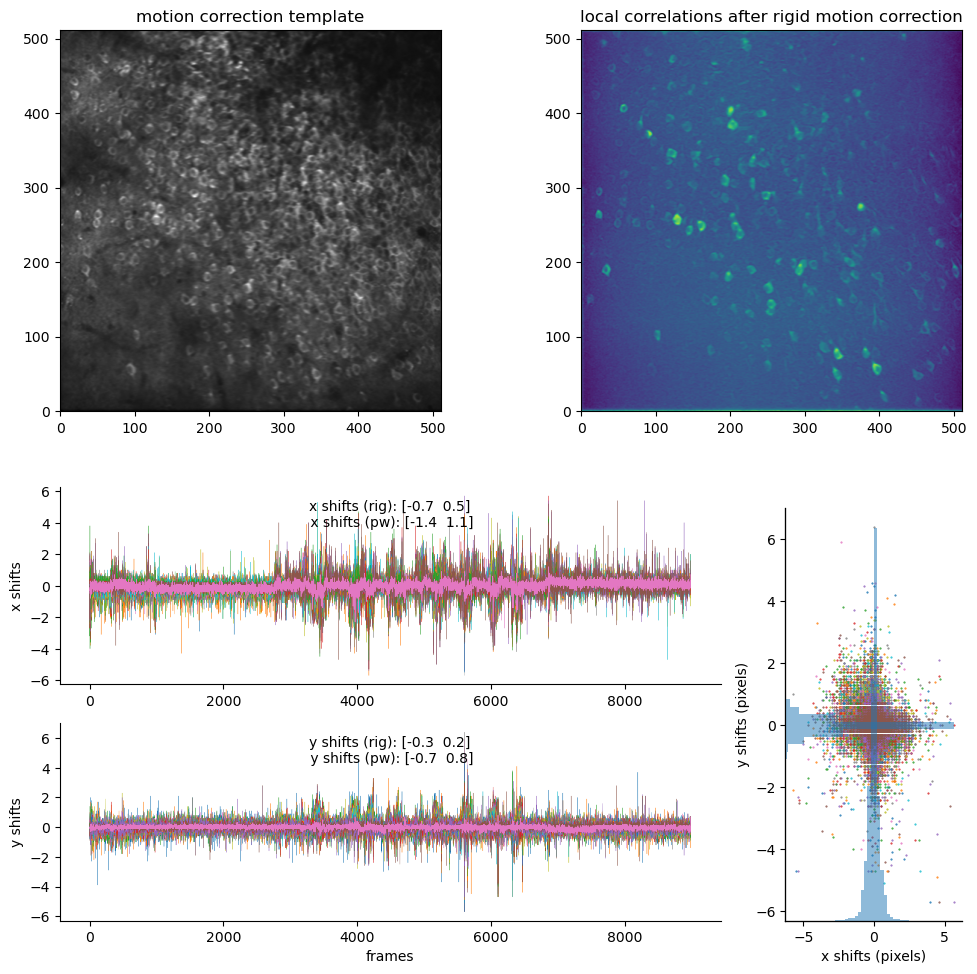

	Motion correction done @t = Mon Feb 16 13:05:26 2026, (time passed: 406.4592065811157)


In [29]:
path_destination = session_path / "tmp"
params = copy.deepcopy(CaImAn_params)
params.update({"fr": 15.0, "decay_time": 0.47})

path_to_stack = [file for file in session_path.iterdir() if file.suffix == ".tif"][0]

# path_to_stack
path_to_motion_correct = motion_correct(
    path_to_stack,
    params,
    path_destination=path_destination,
    n_processes=4,
    plot=True,
)

In [30]:
params["fnames"] = [path_to_motion_correct]
# params["fr"] = 15.0
# params["decay_time"] = 0.4  # GCaMP6f[1]

params["p"] = 2
# params["epochs"] = 1
# params["show_movie"] = False  # whether to display movie while fitting
params["n_processes"] = n_processes
params["init_method"] = "cnmf"
params

{'fr': 15.0,
 'decay_time': 0.47,
 'dxy': 0.9647998794000152,
 'rf': 48,
 'stride': 8,
 'border_pix': 0,
 'nb': 2,
 'gSig': [10, 10],
 'gSiz': (21, 21),
 'min_SNR': 2.5,
 'SNR_lowest': 1.0,
 'rval_thr': 0.8,
 'rval_lowest': -1,
 'min_cnn_thr': 0.9,
 'cnn_lowest': 0.1,
 'use_cnn': True,
 'motion_correct': False,
 'epochs': 1,
 'normalize': True,
 'init_batch': 1000,
 'init_method': 'cnmf',
 'dist_shape_update': True,
 'update_freq': 1000,
 'use_dense': False,
 'merge_thr': 0.65,
 'max_shifts': (12, 12),
 'strides': (96, 96),
 'overlaps': (24, 24),
 'max_deviation_rigid': 6,
 'pw_rigid': True,
 'show_movie': False,
 'save_online_movie': False,
 'fnames': ['/home/wollex/caiman_data/temp/ad_homo#587_hp_16x1.5x_147um_97v96v_57p_res_lave2_am_els__d1_512_d2_512_d3_1_order_F_frames_8989.mmap'],
 'p': 2,
 'n_processes': 12}

In [ ]:
cnmf_batch = cnmf.cnmf.load_CNMF(str(result_file))

if use_parallel:
    c, dview, n_processes = caiman.cluster.setup_cluster(
        n_processes=n_processes, single_thread=False
    )
else:
    dview = None
    n_processes = 1

cnmf_batch.params.set("temporal", {"p": 2, "optimize_g": False})
# Yr, dims, num_frames = caiman.load_memmap(str(path_to_motion_correct))
# images = np.reshape(Yr.T, [num_frames] + list(dims), order="C")
# cnmf_batch.mmap_file = str(path_to_motion_correct)
# cnmf_batch = cnmf_batch.refit(images, dview)

Datafile /home/wollex/Data/ScienceData/turnover_analysis/KotaroData/587ad/Session07/neuron_detection_ad_homo#587_hp_16x1.5x_147um_97v96v_57p_res_lave2_am_initial.hdf5 not marked as cnmf
/home/wollex/miniforge3/envs/neuron-detection-bare/lib/python3.12/site-packages/caiman/source_extraction/cnmf/deconvolution.py:1050: RuntimeWarning: divide by zero encountered in log
  return np.sqrt(np.exp(np.mean(np.log(Pxx_ind / 2))))


ValueError: math domain error

In [14]:
session_path = Path(
    "/home/wollex/mnt/hpc_location/analysis/AlzheimerMice_Hayashi/587ad/Session06"
)
result_file = [
    file
    for file in session_path.iterdir()
    if file.stem.startswith(prefix) and file.stem.endswith(suffix)
][0]
print("Processing file:", result_file)

Processing file: /home/wollex/mnt/hpc_location/analysis/AlzheimerMice_Hayashi/587ad/Session06/neuron_detection_ad_homo#587_hp_16x1.5x_153um_98v95v_60p_res_lave2_pm_initial.hdf5


In [15]:
cnmf_batch_06 = cnmf.cnmf.load_CNMF(result_file)

Datafile /home/wollex/mnt/hpc_location/analysis/AlzheimerMice_Hayashi/587ad/Session06/neuron_detection_ad_homo#587_hp_16x1.5x_153um_98v95v_60p_res_lave2_pm_initial.hdf5 not marked as cnmf


In [38]:
cnmf_batch_06.estimates.g[1]

array([ 1.56346226, -0.58365547])

In [ ]:
def ar2_to_tau(a1, a2, f):
    dt = 1 / f
    discriminant = a1**2 + 4 * a2
    lambda1 = (a1 + np.sqrt(discriminant)) / 2
    lambda2 = (a1 - np.sqrt(discriminant)) / 2
    tau1 = -dt / np.log(np.abs(lambda1))
    tau2 = -dt / np.log(np.abs(lambda2))
    return tau1, tau2


GCaMP6s = (0.18, 0.58)
GCaMP6m = (0.1, 0.289)
GCaMP6f = (0.03, 0.15)

for i in range(10):
    tau1 = ar2_to_tau(*cnmf_batch.estimates.g[i], cnmf_batch.params.get("data", "fr"))
    print(f"Session 07, neuron {i}:", tau1)
# tau1 = ar2_to_tau(*cnmf_batch.estimates.g[0], cnmf_batch.params.get("data", "fr"))
# print("Session 07:", tau1)

for i in range(10):
    tau2 = ar2_to_tau(
        *cnmf_batch_06.estimates.g[i], cnmf_batch_06.params.get("data", "fr")
    )
    print(f"Session 06, neuron {i}:", tau2)
# print("Session 06:", tau2)

Session 07, neuron 0: (0.3145144032203252, 0.03443196781277443)
Session 07, neuron 1: (0.17029876025958515, 0.03443196781277443)
Session 07, neuron 2: (0.09432415184778159, 0.03443196781277443)
Session 07, neuron 3: (0.06035138378116006, 0.06035138378116006)
Session 07, neuron 4: (0.05172295183723118, 0.05172295183723118)
Session 07, neuron 5: (0.11843349996628567, 0.03443196781277444)
Session 07, neuron 6: (0.1503047602889533, 0.03218837543103989)
Session 07, neuron 7: (0.3081151035185552, 0.03443196781277444)
Session 07, neuron 8: (0.12748314783501286, 0.03443196781277444)
Session 07, neuron 9: (0.05628488591885671, 0.05628488591885671)
Session 06, neuron 0: (0.3487258699814984, 0.09084189426402814)
Session 06, neuron 1: (1.2339328099489295, 0.1376225816858946)
Session 06, neuron 2: (0.48849434051250035, 0.1578025088242953)
Session 06, neuron 3: (1.075128453074553, 0.1460130037868177)
Session 06, neuron 4: (0.47648814623581676, 0.11025744644975256)
Session 06, neuron 5: (0.3729543589